# Handwritten-digit classification with MLP and CNN

This experiment asks three practical questions:

1. How does replacing sigmoid with ReLU change training under fixed settings?
2. What changes when we add Batch Normalization or increase the learning rate?
3. How does a small convolutional network compare with the dense networks?

The core code is in `models.py` and `training.py`. It defines the layers and
training loop explicitly; PyTorch supplies automatic differentiation and SGD.
The notebook calls the same experiment as the main command:

```bash
python -m neural_network_classification.run_experiment
```

Select the repository's `.venv` kernel, then restart and run all cells. Install
the `neural` extra first if PyTorch is not present:

```bash
python -m pip install -e '.[neural,notebook,dev]'
```

**Data:** this uses scikit-learn's 1,797 UCI optical digit images, which are
8 × 8. They are resized to 28 × 28 for the networks. This is not MNIST, and
resizing does not create additional image detail. Raw images and pixel arrays
are not exported in this notebook or its saved result files.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from neural_network_classification.models import build_mlp, build_cnn
from neural_network_classification.run_experiment import run_experiment, save_results, EXPERIMENTS
from neural_network_classification.plotting import (
    plot_class_counts, plot_learning_curves, plot_accuracy, plot_confusion,
)

%matplotlib inline

## 1. Load, split, and run the shared experiment

Pixel intensities have a documented range of 0–16. We divide by 16 and use
bilinear interpolation with `align_corners=False` to resize each image. Both
steps act independently on each image; no preprocessing parameters are fitted
using held-out data.

We reserve three stratified, disjoint splits with seed 42:

- **Training (60%)** updates weights and BatchNorm running statistics.
- **Validation (20%)** selects a checkpoint and then a model configuration.
- **Test (20%)** evaluates the frozen choices.

All five configurations use 20 epochs, batch size 64, cross-entropy loss, and
SGD with momentum 0.9. CPU execution uses one thread and deterministic
operations. The next cell performs the complete training once and returns
the models, measurements, predictions, and metadata in a dictionary.

,split,images,classes
0,train,1077,10
1,validation,360,10
2,test,360,10


Network input shape: **(1797, 1, 28, 28)** (images, channels, height, width).

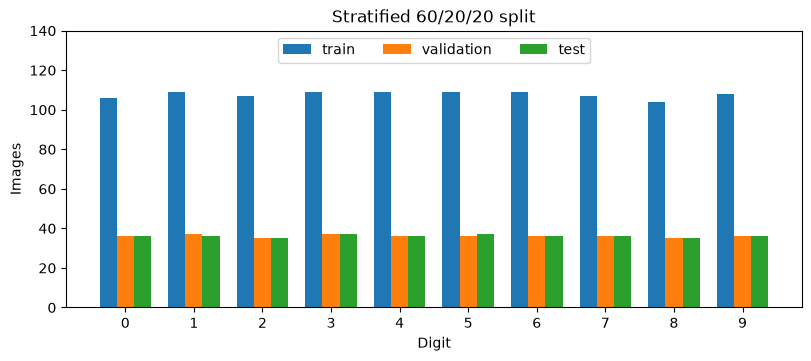

In [2]:
result = run_experiment(epochs=20)
data = result["data"]
split_table = pd.DataFrame([
    {"split": name, "images": len(data[name]),
     "classes": len(data["labels"][data[name]].unique())}
    for name in ("train", "validation", "test")
])
display(split_table)
display(Markdown(f"Network input shape: **{tuple(data['images'].shape)}** "
                 "(images, channels, height, width)."))
plot_class_counts(result)
plt.show()

## 2. Read the architectures

The **MLP** flattens an image into 784 values, applies two hidden layers
(120 and 84 units), and returns ten class scores. We first change only the
activation, then add BatchNorm, then change the learning rate. All four MLPs
start with the same dense-layer weights and use the same shuffled batches.

The **CNN** keeps the spatial layout through two convolution/pooling stages.
Its tensor sizes are:

```text
1×28×28 → 6×28×28 → 6×14×14 → 16×10×10 → 16×5×5
→ flatten 400 → hidden 120 → hidden 84 → output 10
```

This is a LeNet-style design using ReLU, max pooling, and BatchNorm. It is
not an exact historical LeNet-5 reproduction. The architecture uses fewer
parameters than these MLPs, but that alone does not guarantee higher accuracy.

In [3]:
display(pd.DataFrame(EXPERIMENTS))
display(Markdown("**Baseline MLP**\n```text\n" + str(build_mlp()) + "\n```"))
display(Markdown("**CNN**\n```text\n" + str(build_cnn()) + "\n```"))

,name,architecture,activation,batch_norm,learning_rate
0,MLP sigmoid,mlp,sigmoid,False,0.01
1,MLP ReLU,mlp,relu,False,0.01
2,MLP ReLU + BN,mlp,relu,True,0.01
3,MLP ReLU + BN (lr=0.1),mlp,relu,True,0.10
4,CNN,cnn,relu,True,0.01


**Baseline MLP**
```text
Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=120, bias=True)
  (2): Sigmoid()
  (3): Linear(in_features=120, out_features=84, bias=True)
  (4): Sigmoid()
  (5): Linear(in_features=84, out_features=10, bias=True)
)
```

**CNN**
```text
Sequential(
  (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (1): BatchNorm2d(6, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (5): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Flatten(start_dim=1, end_dim=-1)
  (9): Linear(in_features=400, out_features=120, bias=True)
  (10): ReLU()
  (11): Linear(in_features=120, out_features=84, bias=True)
  (12): ReLU()
  (13): Linear(in_features=84, out_features=10, bias=True)
)
```

## 3. Understand the training loop

`training.py` performs these steps for each mini-batch:

```python
optimizer.zero_grad()       # Remove gradients from the previous batch.
logits = model(images)      # Forward pass: ten unnormalized class scores.
loss = loss_function(logits, labels)
loss.backward()            # Compute gradients with automatic differentiation.
optimizer.step()           # Apply momentum SGD updates.
```

For one example with true class $y$ and logits $z$, cross-entropy is

$$L = -z_y + \log\left(\sum_{k=0}^{9} e^{z_k}\right).$$

PyTorch's `CrossEntropyLoss` performs this calculation stably. We do not add
a Softmax layer before it. Prediction simply takes the largest logit.

**Training and evaluation modes matter.** `model.train()` lets BatchNorm use
mini-batch statistics and update its running estimates. `model.eval()` uses
the stored estimates; `torch.no_grad()` disables gradient recording. Validation
and test batches never update BatchNorm statistics or network weights.

After every epoch, the code evaluates the complete training and validation
splits in evaluation mode. These are the curves below; test accuracy is not
monitored during training. Epoch zero is the untrained starting point.

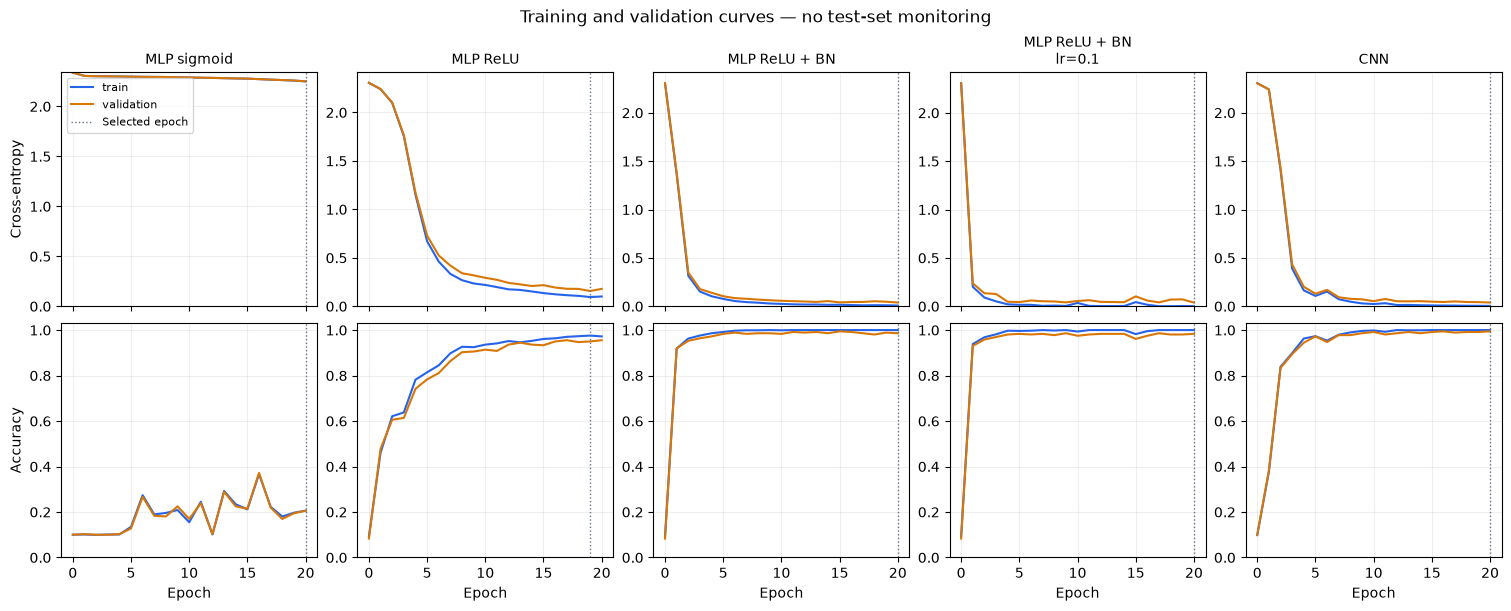

In [4]:
plot_learning_curves(result)
plt.show()

## 4. Restore checkpoints and select a model

For each configuration, retain the state with the **lowest validation loss**,
including the BatchNorm buffers. The dotted line marks that epoch. The last
training epoch is not automatically the best checkpoint.

Next, select the overall configuration by that same validation-loss criterion.
Only after this choice is frozen does the program evaluate all fixed models
on the test set. Equal validation losses keep the first encountered candidate.

In [5]:
metrics = result["metrics"]
display(metrics[["model", "parameters", "best_epoch", "train_accuracy",
                 "validation_loss", "validation_accuracy", "selected_by_validation"]].round(6))
selected = result["metadata"]["selected_model"]
display(Markdown(f"Selected using validation cross-entropy: **{selected}**."))

,model,parameters,best_epoch,train_accuracy,validation_loss,validation_accuracy,selected_by_validation
0,MLP sigmoid,105214,20,0.206128,2.250782,0.205556,False
1,MLP ReLU,105214,19,0.975859,0.157738,0.950000,False
2,MLP ReLU + BN,105622,20,1.000000,0.039051,0.986111,False
3,MLP ReLU + BN (lr=0.1),105622,20,1.000000,0.038844,0.983333,True
4,CNN,61750,20,1.000000,0.038966,0.994444,False


Selected using validation cross-entropy: **MLP ReLU + BN (lr=0.1)**.

## 5. Compare held-out results

The sigmoid baseline has low **training** accuracy as well as low validation
accuracy. Under this initialization, learning rate, and epoch budget, it learns
slowly. This is not evidence that sigmoid networks cannot classify digits;
different settings would need to be selected using validation data.

Replacing sigmoid with ReLU substantially improves this run. Adding BatchNorm
improves it further. The two BatchNorm MLPs have the same final test accuracy
despite their different learning rates. BatchNorm and a larger learning rate
are not guaranteed improvements for every problem.

The CNN has the highest validation accuracy, while the higher-learning-rate
BatchNorm MLP has slightly lower validation cross-entropy and is selected.
Cross-entropy incorporates prediction confidence, so it can rank models
differently from accuracy. The tiny loss differences among the strongest
models do not establish a reliable general ranking.

,model,test_loss,test_accuracy,test_macro_f1,selected_by_validation
0,MLP sigmoid,2.2507,0.2139,0.1119,False
1,MLP ReLU,0.1511,0.9444,0.9435,False
2,MLP ReLU + BN,0.0570,0.9806,0.9804,False
3,MLP ReLU + BN (lr=0.1),0.0566,0.9806,0.9804,True
4,CNN,0.0620,0.9750,0.9748,False


Training-majority baseline: always predict **1**; test accuracy **10.00%**.

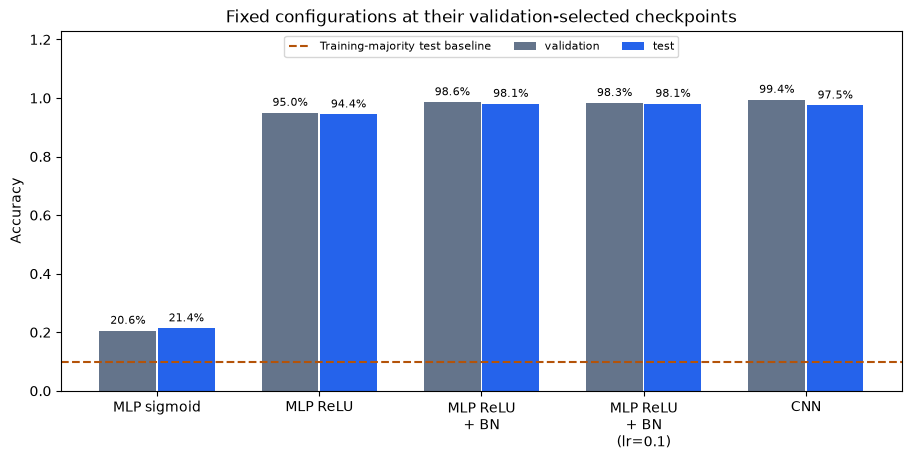

In [6]:
display(metrics[["model", "test_loss", "test_accuracy", "test_macro_f1",
                 "selected_by_validation"]].round(4))
baseline = result["metadata"]["majority_baseline"]
display(Markdown(f"Training-majority baseline: always predict **{baseline['class']}**; "
                 f"test accuracy **{baseline['test_accuracy']:.2%}**."))
plot_accuracy(result)
plt.show()

## 6. Inspect errors from the selected model

The confusion matrix uses actual digits on rows and predicted digits on
columns. Macro-F1 averages the per-class F1 scores equally across the ten
digits. The error table groups the selected model's mistakes without exporting
the source images.

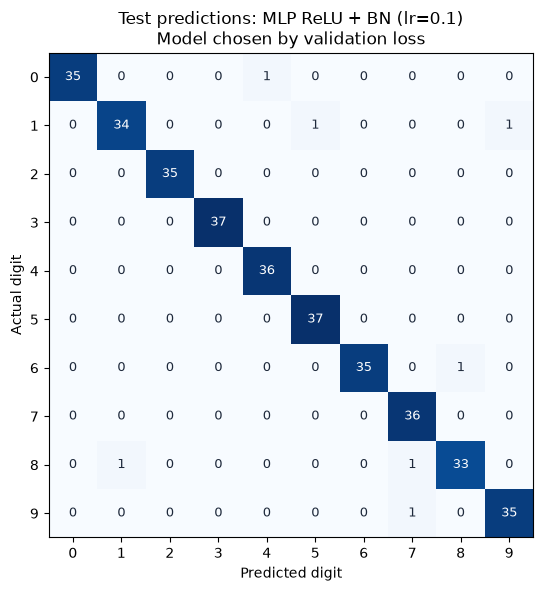

,actual,predicted,count
0,0,4,1
1,1,5,1
2,1,9,1
3,6,8,1
4,8,1,1
5,8,7,1
6,9,7,1


The validation-selected model correctly predicts **353/360** test digits.

In [7]:
plot_confusion(result)
plt.show()

predictions = result["predictions"]
wrong = predictions.loc[predictions["actual"] != predictions[selected], ["actual", selected]]
errors = (wrong.rename(columns={selected: "predicted"})
          .groupby(["actual", "predicted"]).size().reset_index(name="count"))
display(errors)
correct = len(predictions) - len(wrong)
display(Markdown(f"The validation-selected model correctly predicts "
                 f"**{correct}/{len(predictions)}** test digits."))

## 7. Limits of the comparison

- **One split and seed:** small differences need repeated trials before they
  support a model preference. The reported test set is kept separate from
  model and checkpoint selection, but the comparisons are still exploratory.
- **Small, resized images:** these are 8 × 8 digit measurements enlarged to
  28 × 28, not a higher-resolution benchmark. Interpolation adds no new detail.
- **Dataset scope:** scikit-learn supplies a subset of the original UCI data;
  this experiment creates a new split of that subset. Writer IDs are not
  available here, so performance on unseen writers is not established.
- **Fixed training budget:** this is not an exhaustive hyperparameter search
  or a demonstration of every architecture's best achievable score.
- **Reproducibility:** CPU threads, seeds, and deterministic operations are
  fixed. Library versions and platform differences can still affect results.

The project demonstrates network definitions, mini-batch learning, controlled
comparisons, validation-based selection, and held-out evaluation. Its reported
scores apply to this specific experiment.

In [8]:
count = save_results(result)
display(Markdown(f"Saved **{count} result files** to `neural_network_classification/results/`. "
                 "No raw images, pixel arrays, or model weights were exported."))

Saved **8 result files** to `neural_network_classification/results/`. No raw images, pixel arrays, or model weights were exported.

## Data attribution and references

Alpaydin, E. and Kaynak, C. (1998). [Optical Recognition of Handwritten
Digits](https://doi.org/10.24432/C50P49). UCI Machine Learning Repository.
The source page lists [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
We access the library-supplied subset through scikit-learn's
[`load_digits`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html).
Preprocessing divides values by 16 and resizes images; the split is created
for this experiment. Raw data files remain in the installed library.

- PyTorch, [Optimizing Model Parameters](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html).
- PyTorch, [CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html).
- PyTorch, [BatchNorm1d](https://docs.pytorch.org/docs/stable/generated/torch.nn.BatchNorm1d.html).
- PyTorch, [Reproducibility](https://docs.pytorch.org/docs/stable/notes/randomness.html).

- MathWorks, [Create Simple Deep Learning Neural Network for Classification](https://www.mathworks.com/help/deeplearning/ug/create-simple-deep-learning-network-for-classification.html), background for the earlier local prototype.
- LeCun, Bottou, Bengio, and Haffner, [Gradient Based Learning Applied to Document Recognition](https://bottou.org/papers/lecun-98h), 1998, architectural background for the LeNet-style CNN.

The experiment builds on an earlier local prototype that followed the
MathWorks tutorial. The PyTorch program uses a different dataset and
evaluation setup; MathWorks source files and example data are not bundled.
MIT covers this project's own copyrightable contributions, not third-party
materials. See [implementation history and dataset terms](../THIRD_PARTY_NOTICES.md#handwritten-digit-example).